<a href="https://colab.research.google.com/github/Balamurugan-T326/DEEP-LEARNING/blob/main/EXPERIMENT-9/PART-A%2CB%2CC%2CD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Part A: Dataset preparation and text preprocessing

In [4]:
# Experiment 9: Text Classification and Text Generation
# Roll Number: 24BAD016

!pip install -q transformers datasets accelerate scikit-learn sentencepiece

In [5]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoModelForSeq2SeqLM,
    Trainer,
    TrainingArguments,
    pipeline
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("Libraries imported successfully!")

PyTorch version: 2.11.0+cu130
GPU available: True
Libraries imported successfully!


Load the IMDb dataset

In [6]:
# Load IMDb movie review dataset
dataset = load_dataset("stanfordnlp/imdb")

# Use a smaller subset for faster training
train_data = dataset["train"].shuffle(seed=42).select(range(1000))
test_data = dataset["test"].shuffle(seed=42).select(range(300))

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

print("\nSample review:")
print(train_data[0]["text"][:500])

print("\nSample label:", train_data[0]["label"])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Training samples: 1000
Testing samples: 300

Sample review:
There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot similarities... The main character is weak and weirdo, but have "clairvoyance". People like to compare, to judge, to evaluate. How about just enjoying? Funny thing too, people writing Fortier looks Am

Sample label: 1


Explore the class distribution

Class distribution:
Negative reviews (0): 512
Positive reviews (1): 488


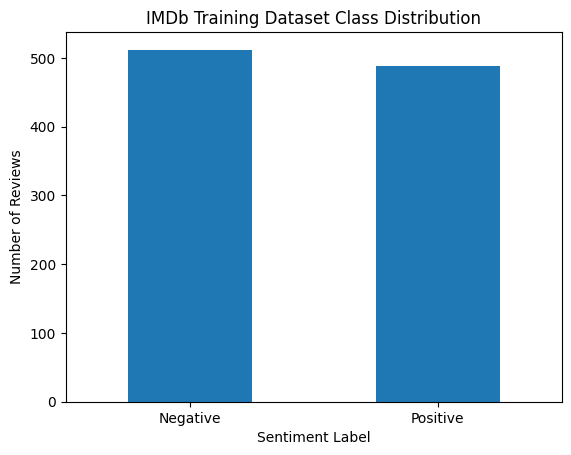

In [7]:
train_labels = train_data["label"]

label_counts = pd.Series(train_labels).value_counts().sort_index()

print("Class distribution:")
print("Negative reviews (0):", label_counts.get(0, 0))
print("Positive reviews (1):", label_counts.get(1, 0))

label_counts.plot(kind="bar", rot=0)
plt.title("IMDb Training Dataset Class Distribution")
plt.xlabel("Sentiment Label")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1], ["Negative", "Positive"])
plt.show()

Load the BERT tokenizer and tokenize the text

In [8]:
# Load pretrained BERT tokenizer
bert_model_name = "google-bert/bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(bert_model_name)

# Tokenize training and testing data
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

tokenized_train = train_data.map(
    tokenize_function, batched=True
)

tokenized_test = test_data.map(
    tokenize_function, batched=True
)

# Remove original text column
tokenized_train = tokenized_train.remove_columns(["text"])
tokenized_test = tokenized_test.remove_columns(["text"])

# Rename labels for model training
tokenized_train = tokenized_train.rename_column("label", "labels")
tokenized_test = tokenized_test.rename_column("label", "labels")

# Convert dataset to PyTorch tensor format
tokenized_train.set_format("torch")
tokenized_test.set_format("torch")

print("Tokenization completed successfully!")
print("Tokenized input shape:", tokenized_train[0]["input_ids"].shape)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Tokenization completed successfully!
Tokenized input shape: torch.Size([128])


Part B: Fine-tuning BERT for text classification

In [9]:
# Load BERT with a classification head for two classes
model = AutoModelForSequenceClassification.from_pretrained(
    bert_model_name,
    num_labels=2
)

print("BERT model loaded successfully!")
print("Number of output classes:", model.config.num_labels)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded successfully!
Number of output classes: 2


Define evaluation metrics

In [10]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

print("Evaluation metrics defined successfully!")

Evaluation metrics defined successfully!


Configure the training parameters

In [11]:
training_args = TrainingArguments(
    output_dir="./bert_results",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=25,
    report_to="none",
    fp16=torch.cuda.is_available()
)

print("Training parameters configured successfully!")

Training parameters configured successfully!


Fine-tune BERT

In [12]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    compute_metrics=compute_metrics
)

# Train the model
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.621164,0.614013,0.696667,0.664804,0.793333,0.723404


TrainOutput(global_step=125, training_loss=0.6662581787109375, metrics={'train_runtime': 18.6231, 'train_samples_per_second': 53.697, 'train_steps_per_second': 6.712, 'total_flos': 65777763840000.0, 'train_loss': 0.6662581787109375, 'epoch': 1.0})

Evaluate the classification model

In [13]:
results = trainer.evaluate()

print("BERT Evaluation Results:")

for metric, value in results.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.621164,0.614013,1,0.696667,0.664804,0.793333,0.723404


BERT Evaluation Results:
eval_loss: 0.6140
eval_accuracy: 0.6967
eval_precision: 0.6648
eval_recall: 0.7933
eval_f1: 0.7234


Test BERT with new text inputs

In [14]:
def predict_sentiment(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    # Use the same device as the model
    device = next(model.parameters()).device
    inputs = {key: value.to(device) for key, value in inputs.items()}

    model.eval()

    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=1)
        predicted_class = torch.argmax(probabilities, dim=1).item()

    sentiment = "Positive" if predicted_class == 1 else "Negative"
    confidence = probabilities[0, predicted_class].item()

    print("Review:", text)
    print("Predicted sentiment:", sentiment)
    print(f"Confidence: {confidence:.4f}")
    print("-" * 50)

predict_sentiment("This movie was excellent and I really enjoyed it.")
predict_sentiment("The movie was boring and a complete waste of time.")

Review: This movie was excellent and I really enjoyed it.
Predicted sentiment: Negative
Confidence: 0.5049
--------------------------------------------------
Review: The movie was boring and a complete waste of time.
Predicted sentiment: Negative
Confidence: 0.6812
--------------------------------------------------


Save the fine-tuned BERT model

In [15]:
model.save_pretrained("./saved_bert_model")
tokenizer.save_pretrained("./saved_bert_model")

print("Fine-tuned BERT model and tokenizer saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuned BERT model and tokenizer saved successfully!


Part C: Implement a Sequence-to-Sequence Application Using Transformers

In [16]:
t5_model_name = "google-t5/t5-small"

t5_tokenizer = AutoTokenizer.from_pretrained(t5_model_name)
t5_model = AutoModelForSeq2SeqLM.from_pretrained(t5_model_name)

device = "cuda" if torch.cuda.is_available() else "cpu"
t5_model = t5_model.to(device)

print("T5-small model loaded successfully!")
print("Device:", device)

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5-small model loaded successfully!
Device: cuda


Generate text using T5

In [17]:
def generate_summary(text, max_output_length=60, num_beams=4):
    # Add the summarization task prefix
    input_text = "summarize: " + text

    inputs = t5_tokenizer(
        input_text,
        return_tensors="pt",
        max_length=512,
        truncation=True
    ).to(device)

    # Generate the output sequence
    with torch.no_grad():
        output_ids = t5_model.generate(
            **inputs,
            max_new_tokens=max_output_length,
            num_beams=num_beams,
            early_stopping=True
        )

    generated_text = t5_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    print("Original Text:")
    print(text)
    print("\nGenerated Summary:")
    print(generated_text)
    print("-" * 60)

    return generated_text


sample_text = """
Artificial intelligence is changing many industries, including education,
healthcare, transportation, and agriculture. Machine learning systems
can analyze large amounts of data, identify patterns, and support
decision-making. However, responsible use of AI requires attention
to privacy, fairness, transparency, and security.
"""

summary = generate_summary(sample_text)

Original Text:

Artificial intelligence is changing many industries, including education,
healthcare, transportation, and agriculture. Machine learning systems
can analyze large amounts of data, identify patterns, and support
decision-making. However, responsible use of AI requires attention
to privacy, fairness, transparency, and security.


Generated Summary:
artificial intelligence is changing many industries, including education, healthcare, transportation, and agriculture. responsible use of AI requires attention to privacy, fairness, transparency, and security.
------------------------------------------------------------


Experiment with different inputs and generation settings

In [18]:
text1 = """
Electric vehicles help reduce tailpipe emissions and can lower
dependence on petrol and diesel. Charging infrastructure,
battery cost, and charging time are important factors in their adoption.
"""

text2 = """
Regular physical activity supports heart health, improves fitness,
and can reduce stress. A balanced diet and adequate sleep also
contribute to a healthy lifestyle.
"""

print("Example 1")
summary1 = generate_summary(
    text1,
    max_output_length=40,
    num_beams=2
)

print("Example 2")
summary2 = generate_summary(
    text2,
    max_output_length=70,
    num_beams=4
)

Example 1
Original Text:

Electric vehicles help reduce tailpipe emissions and can lower
dependence on petrol and diesel. Charging infrastructure,
battery cost, and charging time are important factors in their adoption.


Generated Summary:
electric vehicles help reduce tailpipe emissions and can lower dependence on petrol and diesel. charging infrastructure, battery cost, and charging time are important factors.
------------------------------------------------------------
Example 2
Original Text:

Regular physical activity supports heart health, improves fitness,
and can reduce stress. A balanced diet and adequate sleep also
contribute to a healthy lifestyle.


Generated Summary:
regular physical activity supports heart health, improves fitness, and can reduce stress. a balanced diet and adequate sleep also contribute to a healthy lifestyle.
------------------------------------------------------------


Save the generated outputs

In [19]:
generation_results = pd.DataFrame({
    "Input Text": [text1, text2],
    "Generated Summary": [summary1, summary2]
})

generation_results.to_csv(
    "text_generation_results.csv",
    index=False
)

print(generation_results)
print("\nGenerated outputs saved to text_generation_results.csv")

                                          Input Text  \
0  \nElectric vehicles help reduce tailpipe emiss...   
1  \nRegular physical activity supports heart hea...   

                                   Generated Summary  
0  electric vehicles help reduce tailpipe emissio...  
1  regular physical activity supports heart healt...  

Generated outputs saved to text_generation_results.csv


In [20]:
from google.colab import files

files.download("text_generation_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Part D: Model Testing and Output Analysis

In [21]:
# Test BERT on sample positive and negative reviews
test_reviews = [
    "The acting was wonderful and the story was very interesting.",
    "The movie was terrible and the acting was disappointing."
]

classification_results = []

for review in test_reviews:
    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    ).to(device)

    # BERT and T5 may be on the same device in Colab.
    # Move inputs to the BERT model's device if necessary.
    bert_device = next(model.parameters()).device
    inputs = {k: v.to(bert_device) for k, v in inputs.items()}

    model.eval()
    with torch.no_grad():
        logits = model(**inputs).logits
        prediction = torch.argmax(logits, dim=1).item()

    sentiment = "Positive" if prediction == 1 else "Negative"

    classification_results.append({
        "Review": review,
        "Predicted Sentiment": sentiment
    })

classification_df = pd.DataFrame(classification_results)
print("BERT Classification Results:")
print(classification_df.to_string(index=False))

print("\nT5 Text Generation Result:")
generate_summary(
    "Transformers are deep learning models that understand language "
    "and can be used for sentiment classification, translation, "
    "question answering, and summarization.",
    max_output_length=40,
    num_beams=4
)

BERT Classification Results:
                                                      Review Predicted Sentiment
The acting was wonderful and the story was very interesting.            Positive
    The movie was terrible and the acting was disappointing.            Negative

T5 Text Generation Result:
Original Text:
Transformers are deep learning models that understand language and can be used for sentiment classification, translation, question answering, and summarization.

Generated Summary:
Transformers are deep learning models that understand language and can be used for sentiment classification, translation, question answering, and summarization.
------------------------------------------------------------


'Transformers are deep learning models that understand language and can be used for sentiment classification, translation, question answering, and summarization.'

Display classification metrics graph

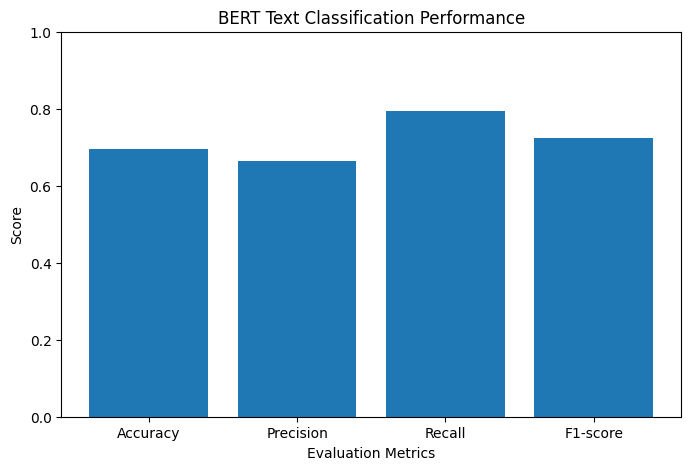

In [22]:
metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]
metric_values = [
    results.get("eval_accuracy", 0),
    results.get("eval_precision", 0),
    results.get("eval_recall", 0),
    results.get("eval_f1", 0)
]

plt.figure(figsize=(8, 5))
plt.bar(metric_names, metric_values)
plt.ylim(0, 1)
plt.title("BERT Text Classification Performance")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.show()